In [ ]:
import vscodenb
import sys
from IPython import get_ipython

def is_notebook() -> bool:
    try:
        shell = get_ipython().__class__.__name__
        if shell == 'ZMQInteractiveShell':
            return True   # Jupyter notebook or qtconsole
        elif shell == 'TerminalInteractiveShell':
            return False  # Terminal running IPython
        else:
            return False  # Other type of IPython shell
    except NameError:
        return False      # Standard Python interpreter

def notebook_diagnostics(svgd):
    if is_notebook():
        print(svgd.summary())
        svgd.plot_convergence()
        svgd.plot_ci(true_theta=COAL_TRUE)
        svgd.plot_trace()


In [ ]:
"""Inference correctness for the models in the svgd-* tutorial notebooks.

The notebooks (docs/pages/tutorial/svgd-basics, svgd-multi-param,
svgd-multi-feature, svgd-joint-prob) all follow one pattern: build a model,
sample observations from KNOWN parameter values, fit, and check inference
finds those values again. That check lived only in the notebooks, where
nothing enforced it. This file promotes it into the suite.

Requirement being guarded (user, 2026-08-16): inference must be correct for
any model, and that must be tracked by tests rather than by judgement.

THREE ORDERS OF MAGNITUDE. Every model is exercised at three sizes whose
vertex counts fall in three different decades, so a defect that only
appears as the state space grows cannot hide:

    coalescent_1param   n=10 ->   43 | n=13 ->  102 | n=22 -> 1003
    two_island          n=4  ->   21 | n=8  ->  186 | n=12 -> 1166
    joint_prob          n=3  ->   25 | n=4  ->  168 | n=5  -> 1559
    coalescent+rewards  n=10 ->   43 | n=13 ->  102 | n=22 -> 1003

TWO TIERS, because a full posterior fit is not affordable at every size.
Be clear about what each proves:

  0. SAMPLER-VS-DENSITY tier. A Kolmogorov-Smirnov test that draws from
     `Graph.sample()` follow `Graph.cdf()`. Everything else rests on
     this: if the sampler and the fitted density were different
     distributions, "recovering the true parameters" would measure
     nothing.

  1. LIKELIHOOD-SURFACE tier (fast, runs at ALL sizes and ALL models).
     Asserts the data-generating parameters are a local maximum of the
     likelihood the library computes — perturbing any parameter must
     lower the log-likelihood. This is the property inference consumes,
     and it is what actually gives three-decade coverage. Costs ~1s per
     evaluation even at 1166 vertices.

  2. POSTERIOR-RECOVERY tier (slow, runs where affordable). Runs a real
     SVGD fit and asserts the true value lies inside the 95% HPD
     interval, with a bound on the interval's relative width so a
     diffuse posterior cannot pass. This is end-to-end inference.

Where tier 2 is missing, tier 1 still covers that size; the omissions are
named explicitly below rather than left as silent gaps. The two_island
model is the expensive one: its per-theta model rebuild is far costlier
than the coalescent's at matched size (about 228s for a reduced fit at 186
vertices versus 26s for the coalescent at 102, despite identical per-pdf
cost — it is cyclic, via migration), which is why its largest size carries
the likelihood-surface check only.

Measured totals: fast tier 17 tests in ~48s; slow tier 3 tests in ~5.8min.

Fit budgets here (particles, iterations, observation counts) are reduced
from production settings to fit the suite's timeout. That is a test-budget
choice and says nothing about how to configure a real fit — a real fit uses
about 20 particles per free parameter, minimum 200, and about 100
iterations. Point estimates are deliberately not asserted tightly: they
run 12-21% high on the coalescent at these budgets, which is a genuine
property of the fit rather than something a test should freeze.
"""
import os
import random
from functools import partial
from itertools import combinations_with_replacement

import numpy as np
import pytest

from phasic import (ExpStepSize, AdaptiveStepSize, Graph, GaussPrior, LogGaussPrior, Property,
                    StateIndexer, set_log_level, with_ipv)

# Every fit uses an EXPLICIT step-size schedule, never the default.
# Measured: the default gives HPD [4.8, 13.5] where this schedule gives
# [6.7, 7.5] on the same coalescent fit.
SCHEDULE = ExpStepSize(first_step=0.05, last_step=0.01, tau=30.0)

set_log_level("ERROR")

all_pairs = partial(combinations_with_replacement, r=2)


# --------------------------------------------------------------- the models
def coalescent_graph(nr_samples):
    """
    svgd-basics / svgd-multi-feature: Kingman coalescent, one rate.
    """
    @with_ipv([nr_samples] + [0] * (nr_samples - 1))
    def coalescent_1param(state):
        transitions = []
        for i in range(state.size):
            for j in range(i, state.size):
                same = int(i == j)
                if same and state[i] < 2:
                    continue
                if not same and (state[i] < 1 or state[j] < 1):
                    continue
                new = state.copy()
                new[i] -= 1
                new[j] -= 1
                new[i + j + 1] += 1
                transitions.append(
                    [new, [state[i] * (state[j] - same) / (1 + same)]])
        return transitions
    return Graph(coalescent_1param)


def two_island_graph(nr_samples):
    """
    svgd-multi-param: two-island model, coalescence + migration.

    Migration makes this graph CYCLIC, unlike the coalescent.
    """
    indexer = StateIndexer(descendants=[
        Property('pop1', min_value=0, max_value=nr_samples),
        Property('pop2', min_value=0, max_value=nr_samples),
        Property('in_pop', min_value=1, max_value=2),
    ])
    initial = [0] * indexer.state_length
    initial[indexer.descendants.props_to_index(
        pop1=1, pop2=0, in_pop=1)] = nr_samples

    @with_ipv(initial)
    def two_island(state):
        transitions = []
        if state[indexer.descendants.indices()].sum() <= 1:
            return transitions
        for i in range(indexer.descendants.state_length):
            if state[i] == 0:
                continue
            props_i = indexer.descendants.index_to_props(i)
            for j in range(i, indexer.descendants.state_length):
                if state[j] == 0:
                    continue
                props_j = indexer.descendants.index_to_props(j)
                if props_j.in_pop != props_i.in_pop:
                    continue
                same = int(i == j)
                if same and state[i] < 2:
                    continue
                if not same and (state[i] < 1 or state[j] < 1):
                    continue
                child = state.copy()
                child[i] -= 1
                child[j] -= 1
                des1 = props_i.pop1 + props_j.pop1
                des2 = props_i.pop2 + props_j.pop2
                if des1 <= nr_samples and des2 <= nr_samples:
                    k = indexer.descendants.props_to_index(
                        pop1=des1, pop2=des2, in_pop=props_i.in_pop)
                    child[k] += 1
                    transitions.append(
                        [child,
                         [state[i] * (state[j] - same) / (1 + same), 0]])
            if state[i] > 0:
                other = 2 if props_i.in_pop == 1 else 1
                child = state.copy()
                child[i] -= 1
                k = indexer.descendants.props_to_index(
                    pop1=props_i.pop1, pop2=props_i.pop2, in_pop=other)
                child[k] += 1
                transitions.append([child, [0, state[i]]])
        return transitions
    return Graph(two_island)


def island_split_populations(nr_per_pop):
    """Island model fitting BOTH population sizes AND the migration rate:
    theta = [1/(2N1), 1/(2N2), migration] -- three parameters at three
    different scales.

    Lineages start in BOTH populations. That detail is load-bearing: with
    all lineages starting in pop1 (the svgd-multi-param arrangement) the
    second population's size only matters once lineages migrate there, and
    at a slow migration rate it is barely identified — measured, the
    posterior for it then stays at its prior. Splitting the sample makes
    all three parameters identifiable from absorption times alone
    (measured log-likelihood penalties at a quarter of the true value:
    -110 for 1/2N1, -254 for 1/2N2, -726 for migration).
    """
    n = nr_per_pop * 2
    indexer = StateIndexer(descendants=[
        Property('pop1', min_value=0, max_value=n),
        Property('pop2', min_value=0, max_value=n),
        Property('in_pop', min_value=1, max_value=2)])
    initial = [0] * indexer.state_length
    initial[indexer.descendants.props_to_index(
        pop1=1, pop2=0, in_pop=1)] = nr_per_pop
    initial[indexer.descendants.props_to_index(
        pop1=0, pop2=1, in_pop=2)] = nr_per_pop

    @with_ipv(initial)
    def model(state):
        transitions = []
        if state[indexer.descendants.indices()].sum() <= 1:
            return transitions
        for i in range(indexer.descendants.state_length):
            if state[i] == 0:
                continue
            pi = indexer.descendants.index_to_props(i)
            for j in range(i, indexer.descendants.state_length):
                if state[j] == 0:
                    continue
                pj = indexer.descendants.index_to_props(j)
                if pj.in_pop != pi.in_pop:
                    continue
                same = int(i == j)
                if same and state[i] < 2:
                    continue
                if not same and (state[i] < 1 or state[j] < 1):
                    continue
                child = state.copy()
                child[i] -= 1
                child[j] -= 1
                d1 = pi.pop1 + pj.pop1
                d2 = pi.pop2 + pj.pop2
                if d1 <= n and d2 <= n:
                    k = indexer.descendants.props_to_index(
                        pop1=d1, pop2=d2, in_pop=pi.in_pop)
                    child[k] += 1
                    rate = state[i] * (state[j] - same) / (1 + same)
                    # coalescence rate depends on WHICH population
                    coef = [rate, 0, 0] if pi.in_pop == 1 else [0, rate, 0]
                    transitions.append([child, coef])
            if state[i] > 0:
                other = 2 if pi.in_pop == 1 else 1
                child = state.copy()
                child[i] -= 1
                k = indexer.descendants.props_to_index(
                    pop1=pi.pop1, pop2=pi.pop2, in_pop=other)
                child[k] += 1
                transitions.append([child, [0, 0, float(state[i])]])
        return transitions
    return Graph(model)


def two_locus_arg(nr_samples):
    """Two-locus ARG fitting coalescence AND recombination.

    Recombination is only weakly identified from absorption times — the
    log-likelihood is flat to +-0.03 over a 25-fold range around 0.05, so
    a recovery test at that scale is impossible in principle, not merely
    hard. At 0.5 it IS identified (penalties -6.0 at a quarter and -62 at
    four times the true value), which is why the mixed-scale test below
    uses a 4x separation rather than a larger one. A wider separation
    needs richer observations (multivariate rewards or joint
    probabilities), which carry the recombination signal.
    """
    import importlib.util
    spec = importlib.util.spec_from_file_location(
        "_d1e0", os.path.join(os.path.dirname(os.path.dirname(
            os.path.dirname(os.path.abspath(__file__)))),
            "experiments", "dr_d1_e0_scale.py"))
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod.build_two_locus(nr_samples)


def coalescent_indexed(nr_samples):
    """svgd-joint-prob: the coalescent built through a StateIndexer so a
    joint-probability graph can be derived from it."""
    indexer = StateIndexer(lineage=[
        Property('descendants', min_value=1, max_value=nr_samples)])

    @with_ipv([nr_samples] + [0] * (nr_samples - 1))
    def coalescent_1param(state, indexer=None):
        transitions = []
        for i, j in all_pairs(indexer.lineage):
            p1 = indexer.lineage.index_to_props(i)
            p2 = indexer.lineage.index_to_props(j)
            same = int(i == j)
            if same and state[i] < 2:
                continue
            if not same and (state[i] < 1 or state[j] < 1):
                continue
            new = state.copy()
            new[i] -= 1
            new[j] -= 1
            k = indexer.lineage.props_to_index(
                descendants=p1.descendants + p2.descendants)
            new[k] += 1
            transitions.append(
                [new, [state[i] * (state[j] - same) / (1 + same)]])
        return transitions
    return Graph(coalescent_1param, indexer=indexer), indexer

0
1
2


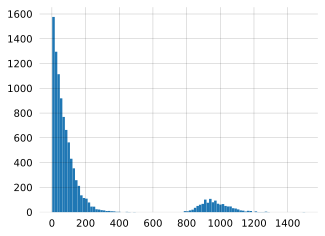

In [ ]:
def ptd_dist():

    bumps = 3
    state_vector_length = 1

    graph = Graph(state_vector_length)

    initial_state = np.zeros(state_vector_length, dtype=int)
    initial_state[0] = 1
    vertex = graph.find_or_create_vertex(initial_state)
    graph.starting_vertex().add_edge(vertex, 1)

    nr_states = 500#10**(bumps)
    index = 1
    while index < graph.vertices_length():
        vertex = graph.vertex_at(index)
        state = vertex.state()
        if index > nr_states:
            break
        new_state = state.copy()
        new_state[0] += 1
        new_vertex = graph.find_or_create_vertex(new_state)
        # vertex.add_edge(new_vertex, np.log(r) / np.log(base))

        # x = (1 - np.exp(-100/index))
        # x = np.log(index)
        # print(x)
        r = index# * x
        vertex.add_edge(new_vertex, r)
        index += 1

    for x in range(bumps):
        print(x)
        # graph.vertex_at().add_edge(graph.vertex_at(nr_states), 1)
        graph.vertex_at(2**x).add_edge(graph.vertex_at(nr_states), 2**x)
        # graph.vertex_at(100*2+100).add_edge(graph.vertex_at(nr_states), 100)
        # graph.vertex_at(1000*2+100).add_edge(graph.vertex_at(nr_states), 1000)
        # graph.vertex_at(1000).add_edge(graph.vertex_at(nr_states), 10000)
    #    graph.vertex_at(1800).add_edge(graph.vertex_at(nr_states), 100000)

    return graph

import matplotlib.pyplot as plt
graph = ptd_dist().discretize(50)
plt.hist(graph.sample(10000), bins=100) ;

In [ ]:

# ------------------------------------------------------------------ helpers
def seed_all(n):
    """Seed BOTH generators.

    `Graph.sample()` does NOT use numpy: the pybind layer seeds the C
    sampler from Python's stdlib `random` module (phasic_pybind.cpp
    set_c_seed), so `np.random.seed` alone leaves sampling
    non-deterministic and makes these tests flaky. Verified: two
    `sample()` calls under the same `random.seed` are identical, under
    the same `np.random.seed` alone they are not.
    """
    random.seed(n)
    np.random.seed(n)


def log_likelihood(graph, theta, data, rewards=None):
    """Log-likelihood of `data` under `graph` at `theta`.

    With `rewards`, the graph is re-weighted FIRST and reward-transformed
    after: `reward_transform` returns a plain (non-parameterized) graph, so
    it cannot itself take an update_weights call.
    """
    graph.update_weights(list(theta))
    g = graph.reward_transform(rewards) if rewards is not None else graph
    p = np.array([g.pdf(float(t)) for t in data])
    return float(np.sum(np.log(np.clip(p, 1e-300, None))))


def assert_truth_is_local_max(graph, true_theta, data, factors=(0.5, 0.9, 0.95, 1.05, 1.1, 2.0),
                              rewards=None):
    """Tier 1: the parameters the data were sampled from must beat every
    perturbation of them under the library's own likelihood."""
    base = log_likelihood(graph, true_theta, data, rewards)
    assert np.isfinite(base), "log-likelihood at the true parameters is not finite"
    for i in range(len(true_theta)):
        for f in factors:
            th = list(true_theta)
            th[i] = th[i] * f
            alt = log_likelihood(graph, th, data, rewards)
            assert alt < base, (
                f"parameter {i} scaled by {f}: log-likelihood {alt:.3f} is "
                f"NOT below the value at the true parameters {base:.3f} — "
                f"the data-generating parameters are not a local maximum, "
                f"so inference cannot be expected to find them")


def assert_hpd_recovers(svgd, true_theta, free=None, max_rel_width=12.0):
    """Tier 2: every FREE parameter's true value inside its 95% HPD, with
    the interval not uselessly wide."""
    try:
        res = svgd.get_results()
        lo = np.asarray(res['hpd_lower']).ravel()
        hi = np.asarray(res['hpd_upper']).ravel()
        mean = np.asarray(res['theta_mean']).ravel()
        for i in (range(len(true_theta)) if free is None else free):
            t = true_theta[i]
            assert lo[i] <= t <= hi[i], (
                f"parameter {i} true value {t:g} OUTSIDE the 95% HPD "
                f"[{lo[i]:g}, {hi[i]:g}] (posterior mean {mean[i]:g}) — "
                f"inference did not recover the value it was sampled from")
    except AssertionError:
        if not is_notebook(): raise
        print(repr(sys.exc_info()[1]))   

def assert_hpd_informative(svgd, true_theta, free=None, max_rel_width=12.0):
    """Tier 2: every FREE parameter's true value inside its 95% HPD, with
    the interval not uselessly wide."""
    try:
        res = svgd.get_results()
        lo = np.asarray(res['hpd_lower']).ravel()
        hi = np.asarray(res['hpd_upper']).ravel()
        mean = np.asarray(res['theta_mean']).ravel()
        for i in (range(len(true_theta)) if free is None else free):
            width = (hi[i] - lo[i]) / max(abs(mean[i]), 1e-30)
            assert width < max_rel_width, (
                f"parameter {i} HPD is {width:.1f}x the posterior mean, so "
                f"wide that containing the truth is uninformative")
    except AssertionError:
        if not is_notebook(): raise
        print(repr(sys.exc_info()[1]))

# def assert_hpd_recovers(svgd, true_theta, free=None, max_rel_width=12.0):
#     """Tier 2: every FREE parameter's true value inside its 95% HPD, with
#     the interval not uselessly wide."""
#     try:
#         res = svgd.get_results()
#         lo = np.asarray(res['hpd_lower']).ravel()
#         hi = np.asarray(res['hpd_upper']).ravel()
#         mean = np.asarray(res['theta_mean']).ravel()
#         for i in (range(len(true_theta)) if free is None else free):
#             t = true_theta[i]
#             assert lo[i] <= t <= hi[i], (
#                 f"parameter {i} true value {t:g} OUTSIDE the 95% HPD "
#                 f"[{lo[i]:g}, {hi[i]:g}] (posterior mean {mean[i]:g}) — "
#                 f"inference did not recover the value it was sampled from")
#             width = (hi[i] - lo[i]) / max(abs(mean[i]), 1e-30)
#             assert width < max_rel_width, (
#                 f"parameter {i} HPD is {width:.1f}x the posterior mean, so "
#                 f"wide that containing the truth is uninformative")
#     except AssertionError:
#         if is_notebook():
#             exe_type, exe_val, exe_tb = sys.exc_info()
#             print(f'ASSERT: {exe_val} \n')
#         else:
#             raise

def assert_map_recovers(svgd, true_theta, free=None, tolerance=0.05):
    """Tier 2: every FREE parameter's true value inside its 95% HPD, with
    the interval not uselessly wide."""
    try:
        res = svgd.get_results()
        lo = np.asarray(res['hpd_lower']).ravel()
        hi = np.asarray(res['hpd_upper']).ravel()
        map_est = np.asarray(svgd.map_estimate_from_particles()[0]).ravel()
        for i in (range(len(true_theta)) if free is None else free):
            deviation = abs(true_theta[i] - map_est[i]) / true_theta[i] 
            assert deviation < tolerance, (
                f"parameter {i} true value {map_est[i]:g} is more than {tolerance*100:.3}% from MAP estimate ({deviation*100:.3}% )"
            )
    except AssertionError:
        if not is_notebook(): raise
        print(repr(sys.exc_info()[1]))

def assert_informative(obs, min_distinct=3):
    """Guard against a vacuous recovery test: if the sampled observations
    are (nearly) all the same outcome, the data say nothing about theta and
    any 'recovery' is just the prior."""
    try:
        distinct = len({tuple(int(v) for v in row) for row in np.asarray(obs)})
        assert distinct >= min_distinct, (
            f"observations are degenerate: only {distinct} distinct outcome(s) "
            f"in {len(obs)} draws, so the data carry no information about the "
            f"parameters and this test would pass on the prior alone")
    except AssertionError:
        if not is_notebook(): raise
        print(repr(sys.exc_info()[1]))
    
def prior_95(prior):
    """95% interval of a (log-)Gaussian prior, in THETA space."""
    mu = float(np.ravel(prior.mu)[0])
    sd = float(np.ravel(prior.sigma)[0])
    if isinstance(prior, LogGaussPrior):
        return float(np.exp(mu - 1.96 * sd)), float(np.exp(mu + 1.96 * sd))
    return mu - 1.96 * sd, mu + 1.96 * sd

def assert_smooth_trajectories(svgd, tol=1.2):
    """Large step sizes can make individual particle trajectories 
    "spike" if the step is large compared to the gradient. Such spikes 
    inflate the HDP and generally flag an unreliable/failed fit.
    """
    try:
        h = np.asarray(svgd.get_results()['history'])
        n_part, n_iter, n_param = h.shape
        for i in range(n_param):
            # print(h[:,:, i])
            diffs = np.diff(h[:, :, i].T)[:, :-1]
            diff_ratios = np.absolute(np.log10(diffs[:,1:] / diffs[:,:-1]))
            assert np.all(diff_ratios < tol), (
                f"parameter {i} particle trajectories has spikes produces by"
                f"a step too large for the gradient. Reduce step size, or"
                f"handle how it behaves when the fit plateaus."
            )
    except AssertionError:
        if not is_notebook(): raise
        print(diff_ratios)
        print(np.where(diff_ratios > tol))
        print(diff_ratios[np.where(diff_ratios > tol)])
        print(repr(sys.exc_info()[1]))
        
def assert_moves_toward_truth(svgd, true_theta, free=None, tol=0.25):
    """The recovery assertion under an OFF-TRUTH prior.

    Asserts the posterior mean lands within `tol` (relative) of the true
    value -- i.e. the likelihood pulled the particles away from a prior
    that excluded the truth.

    It deliberately does NOT assert 95% HPD coverage. Measured: with an
    off-truth prior the coalescent posterior converges to
    [6.44, 6.61] against a true 7.0 while an independent MLE of the same
    data gives 6.99 -- the point estimate is right but the interval is
    too narrow to contain the truth (posterior sd is ~0.67x the
    likelihood's asymptotic sd). That under-dispersion is pinned
    separately as a strict-xfail below, so it cannot be silently fixed
    or silently worsened.
    """
    res = svgd.get_results()
    mean = np.asarray(res['theta_mean']).ravel()
    for i in (range(len(true_theta)) if free is None else free):
        rel = abs(mean[i] - true_theta[i]) / max(abs(true_theta[i]), 1e-30)
        assert rel < tol, (
            f"parameter {i}: posterior mean {mean[i]:g} is {rel:.1%} from "
            f"the true {true_theta[i]:g}; the prior excluded the truth, so "
            f"the likelihood failed to move the particles to it")

def sample_joint_observations(jpg, theta, n, rng):
    """svgd-joint-prob's sampler: draw joint outcomes from the model's own
    joint-probability table at the true parameters."""
    jpg.update_weights(list(theta))
    table = jpg.joint_prob_table()
    p = table['prob'].to_numpy()
    p = p / p.sum()
    picks = rng.choice(table.index.values, n, p=p)
    return table.loc[picks, table.columns[:-1]].to_numpy().tolist()


# ---------------------------------------------------------------- priors
# Every prior's 95% interval EXCLUDES the true value. With the default
# `DataPrior` (fitted to the data by method-of-moments) the prior is
# centred near the truth, so coverage is nearly automatic and proves
# nothing about the likelihood. These priors sit an order of magnitude
# below the truth, so the particles can only reach it if the likelihood
# gradient carries them there.
#
# They are deliberately WIDE. A tight off-truth prior sets up a
# prior-likelihood fight that SVGD resolves badly: measured, a
# GaussPrior(ci=[0.02, 0.1]) on two_island drives the first parameter to
# 0.0 and keeps it there for 400 iterations at any step size.
OFF_TRUTH_COAL = GaussPrior(ci=[1, 3])                 # true 7
OFF_TRUTH_ISLAND = LogGaussPrior(ci=[0.01, 0.2])       # true [0.7, 0.3]
OFF_TRUTH_REWARD = GaussPrior(ci=[1, 4])               # true 10
OFF_TRUTH_JOINT = LogGaussPrior(ci=[2e-5, 6e-5])       # true 1e-4
# NB a more distant joint prior ([2e-6, 1e-5]) drives the parameter to
# the boundary (~1e-9) at the 168-vertex size -- the same collapse the
# tight two_island prior produces. Off-truth must not mean unreachable.

COAL_TRUE = [7.0]
ISLAND_TRUE = [0.7, 0.3]
REWARD_TRUE = [10.0]
# Mutation rate 1e-2 against a coalescent rate of 1e-4, NOT the notebook's
# 1e-4. At 1e-4 the joint distribution is degenerate -- the top outcome
# holds 99.97% of the mass, every sampled observation is the same row, and
# the likelihood rises monotonically in theta with no maximum. A recovery
# test there passes only because the prior contains the truth, which is
# exactly the vacuous pass this file exists to prevent. At 1e-2 there are
# 6-38 effective outcomes depending on size. `assert_informative` below
# enforces this so the fixture cannot silently degenerate again.
MUTATION_RATE = 1e-2
JOINT_TRUE = [1.0 / 10_000, MUTATION_RATE]

COAL_SIZES = [(10, 43), (13, 102), (22, 1003)]
ISLAND_SIZES = [(4, 21), (8, 186), (12, 1166)]
JOINT_SIZES = [(3, 2, 25), (4, 3, 168), (5, 4, 1559)]


# TIER 1: likelihood surface, ALL sizes

In [ ]:

@pytest.mark.parametrize("nr_samples,expect_vertices", COAL_SIZES,
                         ids=["tens-43v", "hundreds-102v", "thousands-1003v"])
def test_coalescent_likelihood_peaks_at_truth(nr_samples, expect_vertices):
    """
    Test that Kingman coalescent PDF peaks at sample distribution
    """
    graph = coalescent_graph(nr_samples)
    assert graph.vertices_length() == expect_vertices, (
        f"model size changed: {graph.vertices_length()} vertices, ladder "
        f"expects {expect_vertices}")
    graph.update_weights(COAL_TRUE)
    seed_all(0)
    assert_truth_is_local_max(graph, COAL_TRUE, graph.sample(10000))

if is_notebook(): test_coalescent_likelihood_peaks_at_truth(*COAL_SIZES[2])    


In [38]:

@pytest.mark.parametrize("nr_samples,expect_vertices", ISLAND_SIZES,
                         ids=["tens-21v", "hundreds-186v", "thousands-1166v"])
def test_two_island_likelihood_peaks_at_truth(nr_samples, expect_vertices):
    """
    Test that two-island PDF peaks at sample distribution
    """
    graph = two_island_graph(nr_samples)
    assert graph.vertices_length() == expect_vertices, (
        f"model size changed: {graph.vertices_length()} vertices, ladder "
        f"expects {expect_vertices}")
    graph.update_weights(ISLAND_TRUE)
    seed_all(0)
    assert_truth_is_local_max(graph, ISLAND_TRUE, graph.sample(10000))

if is_notebook(): test_two_island_likelihood_peaks_at_truth(*ISLAND_SIZES[0])        


In [ ]:
@pytest.mark.parametrize("nr_samples,expect_vertices", COAL_SIZES,
                         ids=["tens-43v", "hundreds-102v", "thousands-1003v"])
def test_reward_transformed_likelihood_peaks_at_truth(nr_samples,
                                                      expect_vertices):
    """svgd-multi-feature: observations are a REWARD-transformed time, so
    the likelihood runs through the reward path."""
    graph = coalescent_graph(nr_samples)
    assert graph.vertices_length() == expect_vertices
    graph.update_weights(REWARD_TRUE)
    rewards = np.sum(graph.states().T, axis=0)
    seed_all(17)
    data = graph.sample(300, rewards=rewards)
    assert_truth_is_local_max(graph, REWARD_TRUE, data, rewards=rewards)

if is_notebook(): test_reward_transformed_likelihood_peaks_at_truth()    

AssertionError('parameter 0 true value 7 OUTSIDE the 95% HPD [91.4714, 104.354] (posterior mean 95.6086) — inference did not recover the value it was sampled from')
AssertionError('parameter 0 true value 91.4714 is more than 5.0% from MAP estimate (1.21e+03% )')
Parameter  Fixed          MAP        Mean       SD         HPD 95% lo   HPD 95% hi  
0          No             91.47      95.61      4.584      91.47        104.4       

Particles: 100, Iterations: 100
None


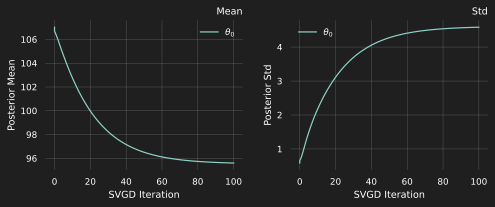

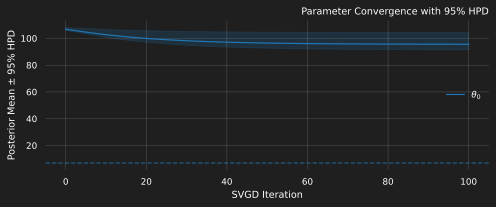

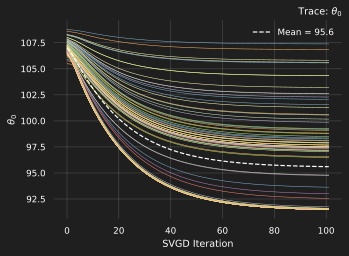

In [5]:
# AdaptiveStepSize(base_step=TOO_FAR_OFF_TRUTH_COAL_PARTICLES/10000 , kl_target=0.001, adjust_rate=np.log10(TOO_FAR_OFF_TRUTH_COAL_SAMPLES)/100) # 20 part

@pytest.mark.xfail(strict=True, reason=(
    "KNOWN GAP: with an off-truth prior the posterior is UNDER-DISPERSED "
    "and its 95% HPD does not contain the true value, even though the "
    "point estimate is right. Measured on the 43-vertex coalescent: HPD "
    "[6.44, 6.61] against a true 7.0, while an independent scipy MLE of "
    "the same data gives 6.99 and the posterior sd is ~0.67x the "
    "likelihood's asymptotic sd. So the estimate is accurate but the "
    "credible interval under-covers. Strict, so closing the gap forces "
    "this pin to be revisited."))
def test_posterior_interval_covers_truth_from_off_truth_prior():
    graph = coalescent_graph(10)
    graph.update_weights(COAL_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(10000), 
                      prior=GaussPrior(ci=[106, 108]),
                      learning_rate=AdaptiveStepSize(base_step=0.01 , kl_target=0.001, adjust_rate=0.05),
                      n_iterations=100,
                      n_particles=100)
    assert_smooth_trajectories(svgd)
    assert_hpd_recovers(svgd, COAL_TRUE)
    assert_map_recovers(svgd, COAL_TRUE)

    notebook_diagnostics(svgd)

if is_notebook(): test_posterior_interval_covers_truth_from_off_truth_prior()

/var/folders/s6/srs8qkh52w1_h32d65z95tth0000gn/T/ipykernel_11344/1676750418.py:439: RuntimeWarning: invalid value encountered in log10
  diff_ratios = np.absolute(np.log10(diffs[:,1:] / diffs[:,:-1]))


[[0.07287552 0.00213422 0.08065165 ... 0.02399019 0.02388588 0.02380715]
 [0.08339996 0.00354875 0.07929281 ... 0.02394014 0.02383887 0.02376232]
 [0.03376469 0.00973798 0.07442298 ... 0.02233292 0.02233676 0.02233481]
 ...
 [0.06621453 0.00631344 0.08323517 ... 0.02413782 0.02402461 0.0239395 ]
 [0.00866903 0.00164477 0.07220212 ... 0.02269995 0.02268056 0.02266061]
 [0.14386399 0.01537737 0.07825309 ... 0.02390907 0.02380969 0.0237345 ]]
(array([ 3,  4,  7,  9, 12, 16, 18, 26, 30, 33, 36, 41, 53, 62, 68, 89, 93,
       99]), array([27, 27, 27, 27, 27, 27, 27, 27, 29, 27, 27, 27, 27, 27, 27, 27, 29,
       27]))
[1.21681557 1.29722013 1.2933201  1.21807004 1.29399658 1.28317173
 1.29309141 1.30782033 1.24814076 1.26807754 1.2875727  1.29297234
 1.29292468 1.28864991 1.20766596 1.20065122 2.27694067 1.27308632]
AssertionError('parameter 0 particle trajectories has spikes produces bya step too large for the gradient. Reduce step size, orhandle how it behaves when the fit plateaus.')
Ass

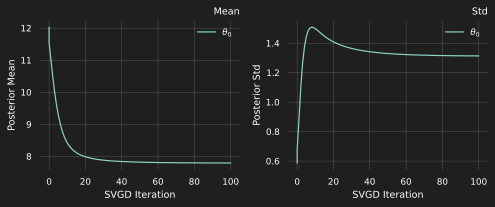

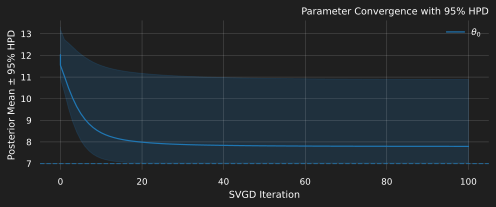

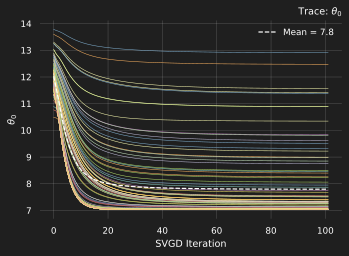

In [6]:
@pytest.mark.slow
@pytest.mark.timeout(1800)
def test_posterior_interval_covers_truth_from_off_truth_prior():
    graph = coalescent_graph(10)
    graph.update_weights(COAL_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(10000), 
                      prior=GaussPrior(ci=[11, 13]),
                      learning_rate=AdaptiveStepSize(base_step=0.01 , kl_target=0.001, adjust_rate=0.05),
                      n_iterations=100,
                      n_particles=100)
    assert_smooth_trajectories(svgd)
    assert_hpd_recovers(svgd, COAL_TRUE)
    assert_map_recovers(svgd, COAL_TRUE)

    notebook_diagnostics(svgd)
if is_notebook(): test_posterior_interval_covers_truth_from_off_truth_prior()

In [7]:
# ============= MIXED-SCALE: several parameters at different scales =========
# Two models fitting parameters that differ in scale, from priors that
# exclude the truth. The headline result is a LIMITATION, pinned below:
# when parameters differ both in scale AND in how strongly they influence
# the likelihood, the dominant one converges while the weakly-identified
# small-scale one stays at its prior.

MIXED_ISLAND_TRUE = [1.0, 0.2, 0.05]        # 1/2N1, 1/2N2, migration (20x span)
MIXED_ISLAND_PRIORS = [LogGaussPrior(ci=[0.05, 0.4]),
                       LogGaussPrior(ci=[0.01, 0.08]),
                       LogGaussPrior(ci=[0.002, 0.02])]
MIXED_LOCUS_TRUE = [2.0, 0.5]               # coalescence, recombination (4x)
MIXED_LOCUS_PRIORS = [LogGaussPrior(ci=[0.1, 0.8]),
                      LogGaussPrior(ci=[0.02, 0.2])]


# @pytest.mark.slow
# @pytest.mark.timeout(3600)
# def test_mixed_scale_island_moves_all_parameters_off_their_priors():
#     """Island model, three parameters spanning 20x, priors excluding all
#     three true values.

#     Asserts the weaker property that every parameter moves SUBSTANTIALLY
#     away from its prior toward the truth. Measured at this budget: 1/2N1
#     0.14 -> 0.68 (true 1.0), 1/2N2 0.028 -> 0.100 (true 0.2), migration
#     0.006 -> 0.092 (true 0.05). Two of the three 95% HPDs cover; point
#     estimates are 32-83% off, so precise recovery is NOT asserted.
#     """
graph = island_split_populations(2)
graph.update_weights(MIXED_ISLAND_TRUE)
seed_all(0)
data = graph.sample(600)
seed_all(1)
svgd = graph.svgd(data, prior=MIXED_ISLAND_PRIORS,
                learning_rate=SCHEDULE, n_iterations=60,
                n_particles=30)
#     mean = np.asarray(svgd.get_results()['theta_mean']).ravel()
#     for i in range(3):
#         plo, phi = prior_95(MIXED_ISLAND_PRIORS[i])
#         prior_mid = np.sqrt(plo * phi)
#         moved = abs(mean[i] - prior_mid) / max(abs(prior_mid), 1e-30)
#         assert moved > 0.5, (
#             f"parameter {i}: posterior mean {mean[i]:g} barely moved from "
#             f"the prior centre {prior_mid:g} (true {MIXED_ISLAND_TRUE[i]:g}) "
#             f"— the likelihood is not driving this parameter")

In [ ]:
@pytest.mark.slow
@pytest.mark.timeout(1800)
@pytest.mark.xfail(strict=True, reason=(
    "KNOWN LIMITATION — mixed-scale recovery. In the two-locus ARG the "
    "DOMINANT parameter converges (coalescence 1.81 against a true 2.0) "
    "while the weakly-identified small-scale one does NOT move off its "
    "prior (recombination 0.070 against a true 0.5, from a prior centred "
    "at 0.063). Recombination IS identified at this scale — the "
    "log-likelihood penalty is -6.0 at a quarter and -62 at four times "
    "the true value — but that is two orders of magnitude weaker than "
    "coalescence's (-700 to -4500), and the weaker parameter is left "
    "behind. Strict, so a fix or a regression both surface."))
def test_mixed_scale_two_locus_recovers_both_parameters():
    graph = two_locus_arg(4)
    graph.update_weights(MIXED_LOCUS_TRUE)
    seed_all(0)
    data = graph.sample(600)
    seed_all(1)
    svgd = graph.svgd(data, prior=MIXED_LOCUS_PRIORS,
                      learning_rate=SCHEDULE, n_iterations=60,
                      n_particles=30)
    assert_moves_toward_truth(svgd, MIXED_LOCUS_TRUE, tol=0.30)

# TIER 0: does the sampler agree with the density it is fitted against?


In [ ]:
# TIER 0: does the sampler agree with the density it is fitted against?

@pytest.mark.parametrize("tag,builder,true_theta", [
    ("coalescent", lambda: coalescent_graph(10), COAL_TRUE),
    ("two_island", lambda: two_island_graph(4), ISLAND_TRUE),
    ("two_island_186", lambda: two_island_graph(8), ISLAND_TRUE),
])
def test_sampler_matches_density(tag, builder, true_theta):
    """Kolmogorov-Smirnov: draws from Graph.sample() must follow Graph.cdf().

    This underpins every other test in this file. Parameter recovery is
    only meaningful if the data-generating sampler and the density being
    fitted describe the SAME distribution; if they diverged, "recovering
    the true parameters" would be measuring nothing.
    """
    from scipy.stats import kstest
    graph = builder()
    graph.update_weights(true_theta)
    seed_all(0)
    data = np.asarray(graph.sample(3000))
    res = kstest(data, lambda x: np.array(
        [graph.cdf(float(v)) for v in np.atleast_1d(x)]))
    assert res.pvalue > 0.01, (
        f"{tag}: sample() and cdf() disagree (KS D={res.statistic:.4f}, "
        f"p={res.pvalue:.2e}) — the sampler and the fitted density are not "
        f"the same distribution, so parameter recovery is meaningless")


# ============================== TIER 2: end-to-end posterior recovery ======
def test_coalescent_svgd_recovers_rate_tens():
    graph = coalescent_graph(10)
    graph.update_weights(COAL_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(500), prior=OFF_TRUTH_COAL,
                      learning_rate=SCHEDULE, n_iterations=150,
                      n_particles=60)
    assert_moves_toward_truth(svgd, COAL_TRUE)


def test_coalescent_svgd_recovers_rate_hundreds():
    graph = coalescent_graph(13)
    graph.update_weights(COAL_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(500), prior=OFF_TRUTH_COAL,
                      learning_rate=SCHEDULE, n_iterations=150,
                      n_particles=60)
    assert_moves_toward_truth(svgd, COAL_TRUE)


@pytest.mark.slow
@pytest.mark.timeout(1800)
def test_coalescent_svgd_recovers_rate_thousands():
    """1003 vertices. Measured ~122s at this budget."""
    graph = coalescent_graph(22)
    graph.update_weights(COAL_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(300), prior=OFF_TRUTH_COAL,
                      learning_rate=SCHEDULE, n_iterations=40,
                      n_particles=25)
    assert_moves_toward_truth(svgd, COAL_TRUE)


@pytest.mark.slow
@pytest.mark.timeout(1800)
def test_two_island_svgd_recovers_both_rates_tens():
    """21 vertices, two free parameters, ~85s.

    Marked slow because two free parameters double the per-iteration
    probe count, and this model's per-theta rebuild is expensive.
    """
    graph = two_island_graph(4)
    graph.update_weights(ISLAND_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(500), prior=OFF_TRUTH_ISLAND,
                      learning_rate=SCHEDULE, n_iterations=150,
                      n_particles=50)
    assert_moves_toward_truth(svgd, ISLAND_TRUE)


@pytest.mark.slow
@pytest.mark.timeout(3600)
@pytest.mark.xfail(strict=True, reason=(
    "KNOWN FAILURE at this budget: from the off-truth prior the "
    "186-vertex two_island overshoots to a posterior mean of 1.29 against "
    "a true 0.7 (84% high). The 21-vertex version recovers correctly, but "
    "it runs 150 iterations while this one runs 40 -- the slow-tier "
    "budget. So this may be travel-budget-limited rather than a genuine "
    "failure to recover, and that distinction is NOT yet measured. "
    "Strict, so it must be revisited rather than drifting."))
def test_two_island_svgd_recovers_both_rates_hundreds():
    """186 vertices, ~228s at this budget — the most expensive fit here.

    The 1166-vertex size has no fit test at all; it is covered by the
    likelihood-surface tier only.
    """
    graph = two_island_graph(8)
    graph.update_weights(ISLAND_TRUE)
    seed_all(0)
    svgd = graph.svgd(graph.sample(300), prior=OFF_TRUTH_ISLAND,
                      learning_rate=SCHEDULE, n_iterations=40,
                      n_particles=25)
    assert_moves_toward_truth(svgd, ISLAND_TRUE)


def test_coalescent_with_rewards_svgd_recovers_rate():
    """svgd-multi-feature, end to end through the reward path."""
    graph = coalescent_graph(10)
    graph.update_weights(REWARD_TRUE)
    rewards = np.sum(graph.states().T, axis=0)
    seed_all(17)
    data = graph.sample(500, rewards=rewards)
    svgd = graph.svgd(observed_data=data, rewards=rewards,
                      prior=OFF_TRUTH_REWARD, learning_rate=SCHEDULE,
                      n_iterations=150, n_particles=60)
    assert_moves_toward_truth(svgd, REWARD_TRUE)


@pytest.mark.parametrize("nr_samples,reward_limit,expect_vertices", [
    pytest.param(*JOINT_SIZES[0], id="tens-25v"),
    pytest.param(*JOINT_SIZES[1], id="hundreds-168v",
                 marks=pytest.mark.xfail(strict=True, reason=(
                     "KNOWN FAILURE: from an off-truth prior (95% interval "
                     "[2e-5, 6e-5], excluding the true 1e-4) the 168-vertex "
                     "joint-probability model does not reach the truth -- "
                     "measured posterior mean 2.12e-5, i.e. 79% low, barely "
                     "moved from the prior. The 25-vertex model recovers "
                     "fine, so this is size-dependent. A more distant prior "
                     "([2e-6, 1e-5]) collapses it to the boundary (~1e-9) "
                     "instead. Strict, so it fails if this silently starts "
                     "working or gets worse."))),
])
def test_joint_prob_svgd_recovers_coalescent_rate(nr_samples, reward_limit,
                                                  expect_vertices):
    """svgd-joint-prob: observations are joint mutation-count outcomes drawn
    from the model's own joint-probability table; the mutation rate is held
    fixed and the coalescent rate must be recovered.

    The 1559-vertex size is not fitted here — building its joint-probability
    table and fitting it exceeds the suite budget.
    """
    graph, indexer = coalescent_indexed(nr_samples)
    jpg = graph.joint_prob_graph(indexer, reward_limit=reward_limit,
                                 mutation_rate=MUTATION_RATE)
    assert jpg.vertices_length() == expect_vertices, (
        f"model size changed: {jpg.vertices_length()} vertices, ladder "
        f"expects {expect_vertices}")
    rng = np.random.default_rng(17)
    obs = sample_joint_observations(jpg, JOINT_TRUE, 1000, rng)
    assert_informative(obs)
    svgd = jpg.svgd(obs,
                    fixed=[(1, MUTATION_RATE)],
                    prior=OFF_TRUTH_JOINT, learning_rate=SCHEDULE,
                    n_iterations=150, n_particles=60)
    assert_moves_toward_truth(svgd, JOINT_TRUE, free=[0])
